In [1]:
## Load the Parquet data sets
from pathlib import Path
import pandas as pd

# Define project directory
PROJECT_ROOT = Path.cwd().parent

# Define input dataset
input_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "barentswatch_lice_2015_2025.parquet"
)

# Load the dataset
df = pd.read_parquet(input_file)

# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Preview first five observations
display(df.head())

Rows: 613601
Columns: 21


,Uke,År,Lokalitetsnummer,Lokalitetsnavn,Voksne hunnlus,Lus i bevegelige stadier,Fastsittende lus,Trolig uten fisk,Har telt lakselus,Kommunenummer,...,Fylkesnummer,Fylke,Lat,Lon,Lusegrense uke,Over lusegrense uke,Sjøtemperatur,ProduksjonsområdeId,Produksjonsområde,Lusegrense_original
0,53,2015,15196,Aga Ø,0.00,0.03,0.06,Nei,Ja,1219.0,...,12.0,Hordaland,59.845100,5.261367,0.5,Nei,7.5,3.0,Karmøy til Sotra,0.5
1,53,2015,12067,Aldalen,0.10,0.43,0.10,Nei,Ja,1243.0,...,12.0,Hordaland,60.249950,5.571917,0.5,Nei,1.0,3.0,Karmøy til Sotra,0.5
2,53,2015,12982,Aldeøyna,0.20,1.25,0.00,Nei,Ja,1428.0,...,14.0,Sogn og Fjordane,61.310250,4.769050,0.5,Nei,7.8,4.0,Nordhordaland til Stadt,0.5
3,53,2015,11756,Allersholmen,0.26,0.42,0.10,Nei,Ja,1264.0,...,12.0,Hordaland,60.774650,4.853600,0.5,Nei,7.6,4.0,Nordhordaland til Stadt,0.5
4,53,2015,13271,Almurden,NaN,NaN,NaN,Ja,Nei,1749.0,...,17.0,Nord-Trøndelag,64.433235,10.680950,0.5,NaN,NaN,7.0,Nord-Trøndelag med Bindal,0.5


In [2]:
#Inspect column data types

print("Dataset column types:\n")

print(df.dtypes)

Dataset column types:

Uke                           int64
År                            int64
Lokalitetsnummer              int64
Lokalitetsnavn                  str
Voksne hunnlus              float64
Lus i bevegelige stadier    float64
Fastsittende lus            float64
Trolig uten fisk                str
Har telt lakselus               str
Kommunenummer               float64
Kommune                         str
Fylkesnummer                float64
Fylke                           str
Lat                         float64
Lon                         float64
Lusegrense uke              float64
Over lusegrense uke             str
Sjøtemperatur               float64
ProduksjonsområdeId         float64
Produksjonsområde               str
Lusegrense_original          string
dtype: object


In [3]:
# Standardize Column Names
# Objective_ Prepare column names for SQL databases, Python pipelines and dashboards.
# Day 3 — Task 3: Standardize column names

column_mapping = {
    "Uke": "week",
    "År": "year",
    "Lokalitetsnummer": "locality_id",
    "Lokalitetsnavn": "locality_name",
    "Voksne hunnlus": "adult_female_lice",
    "Lus i bevegelige stadier": "mobile_lice",
    "Fastsittende lus": "attached_lice",
    "Trolig uten fisk": "probably_without_fish",
    "Har telt lakselus": "lice_counted",
    "Kommunenummer": "municipality_id",
    "Kommune": "municipality",
    "Fylkesnummer": "county_id",
    "Fylke": "county",
    "Lat": "latitude",
    "Lon": "longitude",
    "Lusegrense uke": "weekly_lice_limit",
    "Over lusegrense uke": "over_lice_limit",
    "Sjøtemperatur": "sea_temperature",
    "ProduksjonsområdeId": "production_area_id",
    "Produksjonsområde": "production_area",
    "Lusegrense_original": "weekly_lice_limit_original"
}

df = df.rename(columns=column_mapping)

print(df.columns.tolist())

['week', 'year', 'locality_id', 'locality_name', 'adult_female_lice', 'mobile_lice', 'attached_lice', 'probably_without_fish', 'lice_counted', 'municipality_id', 'municipality', 'county_id', 'county', 'latitude', 'longitude', 'weekly_lice_limit', 'over_lice_limit', 'sea_temperature', 'production_area_id', 'production_area', 'weekly_lice_limit_original']


In [4]:
# Missing data analysis

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="missing_percent",
    ascending=False
)

display(missing_summary.round(2))

,missing_count,missing_percent
adult_female_lice,296166,48.27
attached_lice,296166,48.27
mobile_lice,296166,48.27
over_lice_limit,296134,48.26
sea_temperature,280132,45.65
production_area,244,0.04
production_area_id,244,0.04
county,127,0.02
locality_name,127,0.02
weekly_lice_limit,127,0.02


### Investigate Why Lice Measurements Are Missing
**Objective**:
Determine whether missing adult female lice values are associated with:
1. Facilities probably without fish.
2. Facilities where sea lice were not counted.


In [5]:
# Investigate missing lice measurements

missing_lice_analysis = pd.crosstab(
    index=[
        df["probably_without_fish"],
        df["lice_counted"]
    ],
    columns=df["adult_female_lice"].isna(),
    margins=True
)

print("Missing adult female lice by facility status:\n")

display(missing_lice_analysis)

Missing adult female lice by facility status:



adult_female_lice                    False    True     All
probably_without_fish lice_counted                        
Ja                    Ja                34       0      34
                      Nei                0  285609  285609
Nei                   Ja            317401       0  317401
                      Nei                0   10557   10557
All                                 317435  296166  613601

In [6]:
## Investigate the 34 Unusual Observations
# Objective: Determine whether the 34 observations contain meaningful sea-lice measurements or potential data-quality problems.
# Day 3 — Task 6: Investigate unusual facility records

unusual_records = df[
    (df["probably_without_fish"] == "Ja") &
    (df["lice_counted"] == "Ja")
]

print("Number of unusual records:", len(unusual_records))

display(
    unusual_records[
        [
            "year",
            "week",
            "locality_id",
            "locality_name",
            "adult_female_lice",
            "mobile_lice",
            "attached_lice",
            "probably_without_fish",
            "lice_counted"
        ]
    ]
)

Number of unusual records: 34


,year,week,locality_id,locality_name,adult_female_lice,mobile_lice,attached_lice,probably_without_fish,lice_counted
558075,2025,52,34018,Dolma N,0.00,0.00,0.00,Ja,Ja
562172,2025,49,10616,Vinnalandet,0.00,0.00,0.00,Ja,Ja
562558,2025,48,21016,Husfjord,0.00,0.00,0.00,Ja,Ja
563455,2025,47,32597,Fjordprakken,0.00,0.00,0.00,Ja,Ja
564478,2025,46,10505,Dragnes,0.00,0.00,0.00,Ja,Ja
567617,2025,43,11399,Bogelva,0.00,0.00,0.00,Ja,Ja
568095,2025,43,13340,Leiholmane,0.00,0.00,0.00,Ja,Ja
568542,2025,43,25855,Tussøya,0.01,0.08,0.00,Ja,Ja
570658,2025,41,15517,Tinnlandet,0.00,0.00,0.00,Ja,Ja
575767,2025,36,45060,Pundsvik I,0.00,0.00,0.00,Ja,Ja


### Create a Data Quality Flag
**Objective**
Create a new column identifying observations that require further investigation.

Instead of deleting questionable data, we will mark it.

In [7]:
# Flag unusual reporting combinations

df["reporting_conflict"] = (
    (df["probably_without_fish"] == "Ja") &
    (df["lice_counted"] == "Ja")
)

# Count flagged observations
print("Reporting conflicts:", df["reporting_conflict"].sum())

# Check distribution by year
print("\nReporting conflicts by year:")

display(
    df.groupby("year")["reporting_conflict"].sum()
)

Reporting conflicts: 34

Reporting conflicts by year:


year
2015     0
2016     0
2017     0
2018     0
2019     0
2020     0
2021     0
2022     0
2023     0
2024     0
2025    34
Name: reporting_conflict, dtype: int64

## Convert Categorical Variables to Boolean
**Objective**
The dataset currently contains reporting indicators stored as text:
- probably_without_fish: "Ja" / "Nei"
- lice_counted: "Ja" / "Nei"
- over_lice_limit: "Ja" / "Nei" / missing

In [8]:
# Convert reporting indicators to Boolean

boolean_columns = [
    "probably_without_fish",
    "lice_counted",
    "over_lice_limit"
]

for col in boolean_columns:
    df[col] = df[col].map({
        "Ja": True,
        "Nei": False
    }).astype("boolean")

# Verify conversion
print(df[boolean_columns].dtypes)

display(df[boolean_columns].head(10))

probably_without_fish    boolean
lice_counted             boolean
over_lice_limit          boolean
dtype: object


,probably_without_fish,lice_counted,over_lice_limit
0,False,True,False
1,False,True,False
2,False,True,False
3,False,True,False
4,True,False,<NA>
5,True,False,<NA>
6,False,True,True
7,False,True,False
8,True,False,<NA>
9,False,True,False


In [9]:
#Validate and convert identifier columns

identifier_columns = [
    "municipality_id",
    "county_id",
    "production_area_id"
]

for col in identifier_columns:

    # Check for values containing decimal fractions
    fractional_values = df[col].dropna() % 1 != 0

    if fractional_values.any():
        raise ValueError(
            f"{col} contains non-integer values"
        )

    # Convert to nullable integer
    df[col] = df[col].astype("Int64")

# Verify the conversion
print(df[identifier_columns].dtypes)

display(df[identifier_columns].head(10))

municipality_id       Int64
county_id             Int64
production_area_id    Int64
dtype: object


,municipality_id,county_id,production_area_id
0,1219,12,3
1,1243,12,3
2,1428,14,4
3,1264,12,4
4,1749,17,7
5,1868,18,9
6,1224,12,3
7,1241,12,3
8,1865,18,9
9,1219,12,3


In [10]:
# Validate numerical measurements

numeric_columns = [
    "adult_female_lice",
    "mobile_lice",
    "attached_lice",
    "sea_temperature"
]

# Calculate descriptive statistics
numeric_summary = df[numeric_columns].describe()

print("Numerical measurement summary:")
display(numeric_summary)

# Count negative values
negative_counts = (df[numeric_columns] < 0).sum()

print("\nNegative values by column:")
print(negative_counts)

Numerical measurement summary:


,adult_female_lice,mobile_lice,attached_lice,sea_temperature
count,317435.000000,317435.000000,317435.000000,333469.000000
mean,0.157497,0.636794,0.190305,9.217091
std,0.289396,1.183952,0.607174,3.689480
min,0.000000,0.000000,0.000000,0.000000
25%,0.010000,0.070000,0.000000,6.300000
50%,0.080000,0.260000,0.030000,8.800000
75%,0.210000,0.720000,0.150000,12.100000
max,17.980000,64.600000,47.660000,196.180000



Negative values by column:
adult_female_lice    0
mobile_lice          0
attached_lice        0
sea_temperature      0
dtype: int64


In [11]:
## Investigate suspicious sea temperatures

suspicious_temperatures = df[
    df["sea_temperature"] > 30
]

print(
    "Observations with temperature above 30°C:",
    len(suspicious_temperatures)
)

display(
    suspicious_temperatures[
        [
            "year",
            "week",
            "locality_id",
            "locality_name",
            "sea_temperature",
            "adult_female_lice",
            "lice_counted",
            "probably_without_fish"
        ]
    ].sort_values(
        by="sea_temperature",
        ascending=False
    )
)

Observations with temperature above 30°C: 30


,year,week,locality_id,locality_name,sea_temperature,adult_female_lice,lice_counted,probably_without_fish
588051,2025,24,13229,Djupedalen,196.18,0.08,True,False
508103,2024,47,27015,Kjøsen,173.44,0.00,True,False
569319,2025,42,13345,Oterstegdalen,142.00,0.00,True,False
604891,2025,9,11298,Storøya Nø,98.00,0.03,True,False
555277,2024,3,12870,Leite,96.00,0.25,True,False
447703,2023,52,32717,Tranøya N,96.00,0.00,True,False
538311,2024,19,31777,Reinvika,81.19,0.04,True,False
597653,2025,15,11721,Bukkeholmen,80.10,0.00,True,False
549854,2024,8,21676,Kråkholmen,79.01,0.12,True,False
546884,2024,11,31777,Reinvika,65.10,0.00,True,False


In [12]:
# Flag and clean suspicious temperatures

# 1. Identify suspicious temperatures
df["temperature_outlier"] = df["sea_temperature"] > 30

# 2. Create an analysis-ready temperature column
df["sea_temperature_clean"] = df["sea_temperature"].mask(
    df["temperature_outlier"]
)

# 3. Verify results
print("Flagged temperatures:", df["temperature_outlier"].sum())

print(
    "Original maximum temperature:",
    df["sea_temperature"].max()
)

print(
    "Cleaned maximum temperature:",
    df["sea_temperature_clean"].max()
)

print(
    "Original missing temperatures:",
    df["sea_temperature"].isna().sum()
)

print(
    "Cleaned missing temperatures:",
    df["sea_temperature_clean"].isna().sum()
)

Flagged temperatures: 30
Original maximum temperature: 196.18
Cleaned maximum temperature: 28.96
Original missing temperatures: 280132
Cleaned missing temperatures: 280162


In [13]:
# Investigate extreme sea-lice values

lice_columns = [
    "adult_female_lice",
    "mobile_lice",
    "attached_lice"
]

for col in lice_columns:

    print(f"\nTop 5 highest values: {col}")

    top_records = df.nlargest(5, col)

    display(
        top_records[
            [
                "year",
                "week",
                "locality_id",
                "locality_name",
                col,
                "lice_counted",
                "probably_without_fish"
            ]
        ]
    )


Top 5 highest values: adult_female_lice


,year,week,locality_id,locality_name,adult_female_lice,lice_counted,probably_without_fish
115668,2017,50,11251,Hysjorda,17.98,True,False
116754,2017,49,11251,Hysjorda,17.18,True,False
517798,2024,38,10989,Labukta V,15.87,True,False
7856,2015,46,12897,Honnhammarvika,13.20,True,False
179633,2018,43,12179,Oslandsurda,11.90,True,False



Top 5 highest values: mobile_lice


,year,week,locality_id,locality_name,mobile_lice,lice_counted,probably_without_fish
119471,2017,47,10311,Storlia,64.60,True,False
352546,2021,37,20796,Skarbukta,63.70,True,False
66385,2016,44,12179,Oslandsurda,59.43,True,False
120554,2017,46,10311,Storlia,40.15,True,False
287412,2020,46,34657,Laberget,38.60,True,False



Top 5 highest values: attached_lice


,year,week,locality_id,locality_name,attached_lice,lice_counted,probably_without_fish
518472,2024,37,35957,Danielsvika,47.66,True,False
523447,2024,33,30117,Skognes,44.17,True,False
517213,2024,39,10726,Uløybukt,43.46,True,False
516336,2024,39,35957,Danielsvika,37.44,True,False
513832,2024,42,30117,Skognes,36.62,True,False


In [14]:
#Identify extreme sea-lice measurements

lice_columns = [
    "adult_female_lice",
    "mobile_lice",
    "attached_lice"
]

# Calculate the 99th percentile for each measurement
lice_thresholds = df[lice_columns].quantile(0.99)

print("99th percentile thresholds:")
print(lice_thresholds)

# Create one flag for each measurement
for col in lice_columns:

    threshold = lice_thresholds[col]

    df[f"{col}_extreme"] = df[col] > threshold

# Count flagged observations
print("\nExtreme observations by measurement:")

for col in lice_columns:
    print(
        col,
        df[f"{col}_extreme"].sum()
    )

99th percentile thresholds:
adult_female_lice    1.20
mobile_lice          5.43
attached_lice        2.43
Name: 0.99, dtype: float64

Extreme observations by measurement:
adult_female_lice 3082
mobile_lice 3169
attached_lice 3168


In [15]:
## Validate compliance indicators

# Select rows where all three required values are available
valid_compliance = df[
    df["adult_female_lice"].notna() &
    df["weekly_lice_limit"].notna() &
    df["over_lice_limit"].notna()
].copy()

# Calculate exceedance using the numeric measurements
valid_compliance["calculated_exceedance"] = (
    valid_compliance["adult_female_lice"] >
    valid_compliance["weekly_lice_limit"]
)

# Compare calculated and reported compliance indicators
valid_compliance["compliance_mismatch"] = (
    valid_compliance["calculated_exceedance"] !=
    valid_compliance["over_lice_limit"]
)

print("Records checked:", len(valid_compliance))

print(
    "Compliance mismatches:",
    valid_compliance["compliance_mismatch"].sum()
)

print("\nMismatch distribution by year:")

display(
    valid_compliance.groupby("year")[
        "compliance_mismatch"
    ].sum()
)

Records checked: 317340
Compliance mismatches: 494

Mismatch distribution by year:


year
2015    84
2016    43
2017    57
2018    51
2019    70
2020    48
2021    36
2022    25
2023    22
2024    27
2025    31
Name: compliance_mismatch, dtype: Int64

In [16]:
## Investigate compliance mismatches

# Select only mismatched observations
mismatches = valid_compliance[
    valid_compliance["compliance_mismatch"]
].copy()

# Calculate the difference from the regulatory threshold
mismatches["difference_from_limit"] = (
    mismatches["adult_female_lice"] -
    mismatches["weekly_lice_limit"]
)

# Display mismatch categories
print("Mismatch categories:")

display(
    pd.crosstab(
        mismatches["calculated_exceedance"],
        mismatches["over_lice_limit"]
    )
)

# Display the first 20 mismatched observations
print("\nFirst 20 mismatched observations:")

display(
    mismatches[
        [
            "year",
            "week",
            "locality_id",
            "locality_name",
            "adult_female_lice",
            "weekly_lice_limit",
            "over_lice_limit",
            "calculated_exceedance",
            "difference_from_limit"
        ]
    ].head(20)
)

Mismatch categories:


over_lice_limit,True
calculated_exceedance,
False,494



First 20 mismatched observations:


,year,week,locality_id,locality_name,adult_female_lice,weekly_lice_limit,over_lice_limit,calculated_exceedance,difference_from_limit
6,2015,53,12086,Alsåkervik,0.5,0.5,True,False,0.0
439,2015,53,24455,Klavelandet,0.5,0.5,True,False,0.0
695,2015,53,11688,Portevika,0.5,0.5,True,False,0.0
2144,2015,52,24696,Ørnøya II,0.5,0.5,True,False,0.0
2160,2015,51,32297,Andholmen 2,0.5,0.5,True,False,0.0
4586,2015,49,30897,Havsundet,0.5,0.5,True,False,0.0
5298,2015,49,14678,Uvåg,0.5,0.5,True,False,0.0
5324,2015,49,11315,Vinkfjorden,0.5,0.5,True,False,0.0
5669,2015,48,14679,Hellfjorden,0.5,0.5,True,False,0.0
6825,2015,47,19977,Jektholmen,0.5,0.5,True,False,0.0


In [17]:
# #  Test an alternative compliance rule

# Calculate exceedance using >= instead of >
valid_compliance["calculated_exceedance_gte"] = (
    valid_compliance["adult_female_lice"] >=
    valid_compliance["weekly_lice_limit"]
)

# Compare with BarentsWatch's reported indicator
valid_compliance["mismatch_gte"] = (
    valid_compliance["calculated_exceedance_gte"] !=
    valid_compliance["over_lice_limit"]
)

# Compare the two methods
print("Records checked:", len(valid_compliance))

print(
    "Mismatches using > :",
    valid_compliance["compliance_mismatch"].sum()
)

print(
    "Mismatches using >=:",
    valid_compliance["mismatch_gte"].sum()
)

# Verify whether all original mismatches occurred at equality
print(
    "Original mismatches exactly at the threshold:",
    (
        mismatches["adult_female_lice"] ==
        mismatches["weekly_lice_limit"]
    ).sum()
)

Records checked: 317340
Mismatches using > : 494
Mismatches using >=: 0
Original mismatches exactly at the threshold: 494


In [18]:
#  Create validated compliance indicator

# 1. Identify observations with sufficient information
valid_mask = (
    df["adult_female_lice"].notna() &
    df["weekly_lice_limit"].notna()
)

# 2. Create a nullable Boolean column
df["calculated_lice_exceedance"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="boolean"
)

# 3. Calculate exceedance only for valid observations
df.loc[valid_mask, "calculated_lice_exceedance"] = (
    df.loc[valid_mask, "adult_female_lice"] >=
    df.loc[valid_mask, "weekly_lice_limit"]
)

# 4. Verify results
print("Total observations:", len(df))

print(
    "Calculated exceedances:",
    df["calculated_lice_exceedance"].sum()
)

print(
    "Missing calculated indicators:",
    df["calculated_lice_exceedance"].isna().sum()
)

print(
    "Indicator data type:",
    df["calculated_lice_exceedance"].dtype
)

Total observations: 613601
Calculated exceedances: 11438
Missing calculated indicators: 296261
Indicator data type: boolean


In [19]:
# # Annual sea-lice exceedance analysis

annual_compliance = df.groupby("year").agg(
    total_observations=("locality_id", "size"),

    eligible_observations=(
        "calculated_lice_exceedance", "count"
    ),

    exceedance_observations=(
        "calculated_lice_exceedance", "sum"
    )
)

# Calculate annual exceedance percentage
annual_compliance["exceedance_rate"] = (
    annual_compliance["exceedance_observations"]
    / annual_compliance["eligible_observations"]
    * 100
)

# Display results
display(annual_compliance.round(2))

,total_observations,eligible_observations,exceedance_observations,exceedance_rate
year,,,,
2015,57105,27318,1643,6.01
2016,56041,26656,1209,4.54
2017,56424,27987,1112,3.97
2018,54925,28157,962,3.42
2019,54947,28964,1186,4.09
2020,56354,30019,982,3.27
2021,55491,29809,827,2.77
2022,55454,28836,798,2.77
2023,55606,29733,556,1.87


In [22]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 35.4 MB/s  0:00:00 35.3 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 67.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 49.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 76.6 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


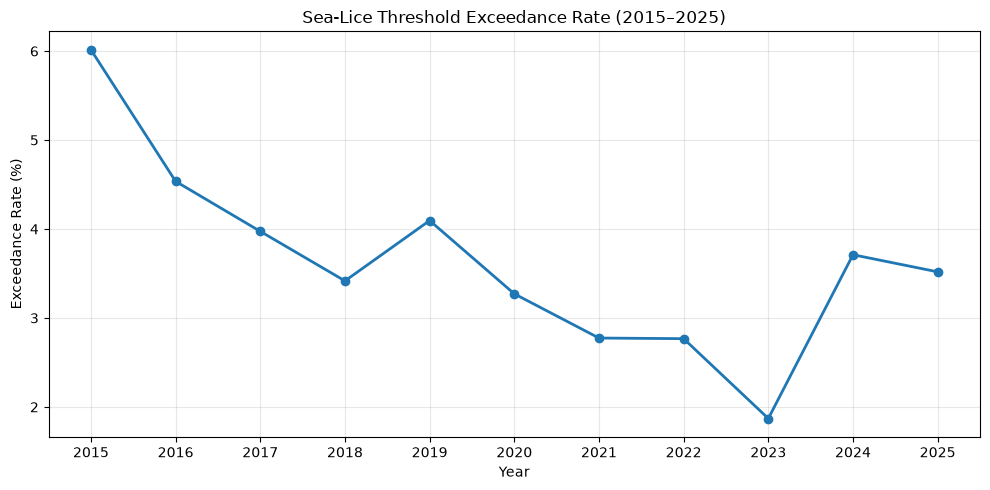

In [23]:
# #  Visualize annual exceedance trends

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    annual_compliance.index,
    annual_compliance["exceedance_rate"],
    marker="o",
    linewidth=2
)

plt.title("Sea-Lice Threshold Exceedance Rate (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Exceedance Rate (%)")

plt.xticks(annual_compliance.index)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Save cleaned dataset

# Define the output file
output_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "barentswatch_lice_cleaned_2015_2025.parquet"
)

# Save the cleaned DataFrame
df.to_parquet(
    output_file,
    engine="pyarrow",
    index=False
)

# Confirm successful export
print("Cleaned dataset saved successfully!")
print("File:", output_file)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("File size (MB):", round(output_file.stat().st_size / 1024**2, 2))

Cleaned dataset saved successfully!
File: /home/user/Documents/Kazi_Academic/Projects/Aquaculture/aquaculture-data-platform/data/processed/barentswatch_lice_cleaned_2015_2025.parquet
Rows: 613601
Columns: 28
File size (MB): 6.44


In [25]:
# # Validate saved Parquet file

# Reload the saved dataset
df_check = pd.read_parquet(output_file)

# Verify data integrity
assert len(df_check) == 613601, "Incorrect number of rows!"
assert len(df_check.columns) == 28, "Incorrect number of columns!"

# Verify column names and data types
assert df_check.columns.equals(df.columns), "Column names do not match!"
assert df_check.dtypes.equals(df.dtypes), "Data types do not match!"

# Verify data values, including missing values
pd.testing.assert_frame_equal(
    df_check,
    df.reset_index(drop=True),
    check_dtype=True
)

print("Parquet validation successful!")
print("Rows:", len(df_check))
print("Columns:", len(df_check.columns))
print("Years:", sorted(df_check["year"].unique()))

Parquet validation successful!
Rows: 613601
Columns: 28
Years: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [26]:
import pandas as pd

df = pd.read_parquet(
    "../data/processed/barentswatch_lice_pipeline_2015_2025.parquet"
)

# Display column names and data types
print(df.dtypes.to_string())

# Check uniqueness of the proposed primary key
duplicate_count = df.duplicated(
    subset=["year", "week", "locality_id"]
).sum()

print("\nDuplicate primary keys:", duplicate_count)

# Check missing values in key columns
print("\nMissing key values:")
print(df[["year", "week", "locality_id"]].isna().sum())

week                            int64
year                            int64
locality_id                     int64
locality_name                     str
adult_female_lice             float64
mobile_lice                   float64
attached_lice                 float64
probably_without_fish         boolean
lice_counted                  boolean
municipality_id                 Int64
municipality                      str
county_id                       Int64
county                            str
latitude                      float64
longitude                     float64
weekly_lice_limit             float64
over_lice_limit               boolean
sea_temperature               float64
production_area_id              Int64
production_area                   str
weekly_lice_limit_original     string
reporting_conflict               bool
temperature_outlier              bool
sea_temperature_clean         float64
adult_female_lice_extreme        bool
mobile_lice_extreme              bool
attached_lic